<a href="https://colab.research.google.com/github/davidawena58-crypto/Projet_2/blob/Adeline-modifications/LENVI2007_part1_and_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Thermal network of a box-type solar cooker — worked example

LENVI2007 – Solar thermal module (Part B). Example notebook, version of 6 October 2026.

This notebook shows how to **build and solve a thermal network** with the matrix formulation of
Naveros, Ghiaus, Ordoñez & Ruiz (2016), and applies it to the setting of the project: a **box cooker with a flat
booster mirror** in **Louvain-la-Neuve**, which must bring **2.0 L of water to 95 °C in 60–75 min**, then keep the
**250 g of pasta at ≥ 90 °C for 10 min** (slides 2, 41 and 43). The method itself is summarised on **slides 38–40**, and the parameters and structure of this notebook in the **appendix, slides 50–51**.

> **Important.** All the cooker data below are **illustrative**, and this example design **deliberately misses the
> 60–75 min target**: section 11 shows why. It is not a design and not a solution of the project; it contains no
> sensitivity study. In the project, the weather comes from the **EPW file** (date and time imposed), the mirror terms from
> the **geometry of your mirrors** (slide 30), and the heat-transfer coefficients from **correlations that you must
> choose and justify** (slides 33–35).

## 1. Formulation (Naveros *et al.*, 2016)

A thermal network is a **directed graph**:

* $n$ **nodes** (temperatures $\theta_l$), each with a thermal capacity $C_l$ and a heat-rate source $f_l$;
* $m$ **branches**, each with a conductance $G_k = 1/R_k$ and possibly a temperature source $b_k$
  (ambient air, sky).

The **incidence matrix** $\mathbf{A}$ ($m \times n$) describes the graph:

$$
a_{kl} = \begin{cases} -1 & \text{if the heat flow } q_k \text{ leaves node } l \\ \;\;0 & \text{if branch } k \text{ is not connected to node } l \\ +1 & \text{if } q_k \text{ enters node } l \end{cases}
$$

Three equations describe the whole network:

| | Equation | Meaning |
|---|---|---|
| (20) | $\mathbf{e} = -\mathbf{A}\boldsymbol{\theta} + \mathbf{b}$ | temperature drop over each branch |
| (21) | $\mathbf{q} = \mathbf{G}\,\mathbf{e}$ | heat rate in each branch (linear law) |
| (22) | $\mathbf{C}\dot{\boldsymbol{\theta}} = \mathbf{A}^T\mathbf{q} + \mathbf{f}$ | energy balance of each node |

Combining them gives the system of differential-algebraic equations (DAE):

$$
\mathbf{C}\,\dot{\boldsymbol{\theta}} = -\mathbf{A}^T\mathbf{G}\mathbf{A}\,\boldsymbol{\theta} + \mathbf{A}^T\mathbf{G}\,\mathbf{b} + \mathbf{f}
\qquad (23)
$$

Nodes with a **negligible capacity** ($C_l = 0$) give **algebraic** equations (instantaneous heat balance);
nodes with $C_l > 0$ give **differential** equations.

**Radiation.** The formulation is linear in $\boldsymbol\theta$ for given conductances. Radiation is written with a
linearised coefficient $h_r = \varepsilon\sigma(T_i+T_j)(T_i^2+T_j^2)$ (slide 36), which is **updated with the current
temperatures** at each time step: $\mathbf{G}$ depends on time, the structure ($\mathbf{A}$) does not.

## 2. Tools and figure style

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

sigma = 5.670e-8      # Stefan-Boltzmann constant, W/(m2 K4)
K0 = 273.15           # 0 degC in K


def style_axes(ax, show_x=True):
    """Course figure style: no grid, no top/right spines, offset axes."""
    ax.grid(False)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_position(('outward', 10))
    ax.spines['left'].set_position(('outward', 10))
    if not show_x:                      # upper panel of a shared-x figure
        ax.spines['bottom'].set_visible(False)
        ax.tick_params(axis='x', which='both', bottom=False, labelbottom=False)

## 3. Site, design day and weather

Louvain-la-Neuve, 21 June, cooking from 11:00 solar time. The weather is a **clear-sky design case** (Hottel beam
model and Liu–Jordan diffuse, slide 25; June normals of Uccle for the air temperature and the dew point, slide 33).

> **In the project**, replace the function `weather(t)` by one that returns the **same keys** from the EPW file
> (`G_bn` = DNI, `G_d` = DHI, `G` = GHI, `Ta`, `Tdp`, `V`), interpolated at the time step. Be careful with time:
> EPW files are in **local standard time**, hour-ending, whereas the solar equations use **solar time**.

In [ ]:
# --- site: Louvain-la-Neuve (as in the slides)
phi    = 50.67     # latitude, deg (north positive)
alt_km = 0.15      # altitude, km (Hottel model)

# --- design day and cooking window (solar time)
n_day     = 172    # 21 June
t_start_h = 11.0   # start of cooking, h (solar time)
t_end_h   = 13.25  # end of the simulation, h (solar time)

# --- weather (clear-sky design case; replace by the EPW values in the project)
Ta_C  = 21.0       # air temperature, degC (June noon, Uccle normal)
Tdp_C = 11.0       # dew point, degC (June, Uccle normal)
V     = 2.0        # wind speed, m/s
rho_g = 0.2        # ground reflectance

Solar geometry (Duffie & Beckman §1.6): declination $\delta$, hour angle $\omega = 15°(t_\mathrm{sol}-12)$, and for a
south-facing surface of slope $\beta$:
$\cos\theta = \cos(\phi-\beta)\cos\delta\cos\omega + \sin(\phi-\beta)\sin\delta$ ($\beta = 0$ gives $\cos\theta_z$).

In [ ]:
G_sc = 1367.0                                         # W/m2 (Duffie & Beckman)
delta = 23.45 * np.sin(np.radians(360 * (284 + n_day) / 365))   # declination, deg
G_on  = G_sc * (1 + 0.033 * np.cos(np.radians(360 * n_day / 365)))

# Hottel clear-sky model, mid-latitude summer (Duffie Eq. 2.8.1, Table 2.8.1)
a0 = 0.97 * (0.4237 - 0.00821 * (6.0 - alt_km)**2)
a1 = 0.99 * (0.5055 + 0.00595 * (6.5 - alt_km)**2)
kH = 1.02 * (0.2711 + 0.01858 * (2.5 - alt_km)**2)

def cos_incidence(t_sol_h, beta):
    """cos(theta) on a south-facing surface of slope beta (deg); beta = 0 gives cos(theta_z)."""
    w = np.radians(15.0 * (t_sol_h - 12.0))
    p, d = np.radians(phi - beta), np.radians(delta)
    return np.cos(p) * np.cos(d) * np.cos(w) + np.sin(p) * np.sin(d)

def weather(t_sol_h):
    """Clear-sky weather at solar time t_sol_h (h). Returns a dictionary.
    In the project: same keys, values read from the EPW file."""
    cz = max(cos_incidence(t_sol_h, 0.0), 0.0)
    tau_b = a0 + a1 * np.exp(-kH / cz) if cz > 0 else 0.0
    G_bn = G_on * tau_b                                  # beam normal, W/m2
    G_d  = G_on * cz * (0.271 - 0.294 * tau_b)           # diffuse horizontal (Liu-Jordan)
    return dict(G_bn=G_bn, G_d=G_d, G=G_bn * cz + G_d, Ta=Ta_C, Tdp=Tdp_C, V=V)

# check against slide 25 (21 June, solar noon): G_bn = 819, G = 833 W/m2
w12 = weather(12.0)
print(f"21 June, solar noon: G_bn = {w12['G_bn']:.0f} W/m2, G = {w12['G']:.0f} W/m2")

21 June, solar noon: G_bn = 819 W/m2, G = 833 W/m2


## 4. The cooker (illustrative data)

Absorbed solar power, as on slide 37: aperture irradiance from the **isotropic-sky model** (slide 28) and one
**flat mirror** that adds a beam-only term $\rho_m\,\gamma\,G_{bn}\cos\theta_m\,A_m$ (slide 30). Here $\gamma$ and
$\cos\theta_m$ are **fixed illustrative numbers**; in the project they follow from the geometry of your mirrors and
change with the position of the Sun.

In [ ]:
# --- geometry (illustrative)
beta_ap = 30.0     # slope of the aperture (glazing), deg, facing south
A_ap    = 0.25     # aperture area, m2  <- design choice examined in section 11
A_abs   = 0.25     # absorber area, m2
A_v     = 0.12     # side area of the pot exposed to the box air, m2
A_lid   = 0.03     # lid of the pot (D = 20 cm), m2
A_walls = 0.90     # insulated walls and bottom, m2

# --- one flat booster mirror (illustrative constants: compute them from YOUR geometry)
A_m, rho_m = 0.30, 0.85    # mirror area (m2) and solar reflectance
gamma_m    = 0.80          # fraction of the reflected beam that reaches the aperture
cos_th_m   = 0.60          # cos of the incidence angle of the beam on the mirror

# --- optics of the glazing and of the absorbing surfaces
tau_g, alpha_g = 0.85, 0.05        # glazing: solar transmittance and absorptance
alpha_abs = alpha_v = 0.95         # black paint
share_v = 0.30                     # share of the transmitted beam intercepted by the pot

# --- infrared emissivities
eps_g, eps_abs, eps_v = 0.90, 0.95, 0.95

# --- convection and conduction (W/(m2 K) unless stated)
h_wind = 2.8 + 3.0 * V      # Watmuff (Duffie §3.15), wind on the glazing
h_gi   = 3.0                # box air -> glazing      (enclosure correlation, Duffie §3.11)
h_ab   = 4.0                # absorber -> box air
h_va   = 4.0                # pot -> box air
U_ins  = 0.8                # insulated walls (k/L of the insulation + casing)
G_cont = 3.0                # contact absorber -> pot bottom, W/K

# --- thermal capacities, J/K
C_abs   = 1000.0                     # blackened plate
C_load0 = 2.0 * 4186 + 0.5 * 900     # 2.0 kg water + 0.5 kg aluminium pot (slide 38)
C_pasta = 0.25 * 1800                # 250 g dry pasta, c = 1.8 kJ/(kg K) (assumed)
T_pasta = 20.0                       # temperature of the dry pasta, degC

# --- cooking criteria (project brief)
T_water0 = 20.0                      # initial temperature of the water, degC
T_target, T_hold, t_hold_min = 95.0, 90.0, 10.0
T_boil = 100.0                       # no superheating: the water stays at 100 degC

print(f"h_wind = {h_wind:.1f} W/(m2 K), C_load = {C_load0:.0f} J/K")

h_wind = 8.8 W/(m2 K), C_load = 8822 J/K


## 5. The network: 4 nodes, 9 branches

![thermal network](attachment:network.png)

| Node | Meaning | Capacity |
|---|---|---|
| 1 `glass` | glazing of the aperture | neglected ($C=0$) |
| 2 `air` | air enclosed in the box | neglected ($C=0$) |
| 3 `absorber` | blackened bottom plate | $C_3$ |
| 4 `load` | pot + 2 L of water (+ pasta once added) | $C_4$ |

| Branch | From → to | Mode |
|---|---|---|
| 1 | $T_\mathrm{amb}$ → glass | wind convection, $h = 2.8 + 3.0\,V$ |
| 2 | $T_\mathrm{sky}$ → glass | radiation to the sky (Berdahl–Martin $T_\mathrm{sky}$) |
| 3 | air → glass | natural convection inside the box |
| 4 | absorber → air | natural convection |
| 5 | load → air | natural convection on the pot |
| 6 | absorber → glass | radiation, parallel plates |
| 7 | absorber → load | contact conduction under the pot |
| 8 | absorber → $T_\mathrm{amb}$ | conduction through the insulation |
| 9 | load → glass | radiation from the lid |

The arrows (from → to) only fix the **positive direction** of each heat flow; a negative value means that the heat
flows the other way. Each branch is written as *(name, origin, destination, conductance)*; when one end is a
temperature source it does not appear in $\mathbf{A}$ but in $\mathbf{b}$, with the sign of Eq. (20):
source → node gives $b_k = +T_\mathrm{source}$, node → source gives $b_k = -T_\mathrm{source}$.
Adding a node or a branch only means editing this list.

In [ ]:
nodes = ['glass', 'air', 'absorber', 'load']
n = len(nodes)

def T_sky(t_sol_h, wx):
    """Berdahl & Martin clear-sky temperature (Duffie Eq. 3.9.2), degC."""
    Ta = wx['Ta'] + K0
    eps_sky = 0.711 + 0.0056 * wx['Tdp'] + 0.000073 * wx['Tdp']**2 + 0.013 * np.cos(np.radians(15 * t_sol_h))
    return Ta * eps_sky**0.25 - K0

def h_rad(Ti, Tj, eps):
    """Linearised radiation coefficient eps*sigma*(Ti+Tj)(Ti^2+Tj^2), temperatures in degC."""
    Ti, Tj = Ti + K0, Tj + K0
    return eps * sigma * (Ti + Tj) * (Ti**2 + Tj**2)

eps_ag = 1 / (1 / eps_abs + 1 / eps_g - 1)    # parallel plates (Duffie Eq. 3.8.4)
eps_lg = 1 / (1 / eps_v + 1 / eps_g - 1)

# branches: (name, origin, destination, conductance function G_k(theta, T), in W/K)
branches = [
    ('wind',        'T_amb',    'glass',    lambda th, T: h_wind * A_ap),
    ('sky',         'T_sky',    'glass',    lambda th, T: h_rad(th['glass'], T['T_sky'], eps_g) * A_ap),
    ('air-glass',   'air',      'glass',    lambda th, T: h_gi * A_ap),
    ('abs-air',     'absorber', 'air',      lambda th, T: h_ab * A_abs),
    ('pot-air',     'load',     'air',      lambda th, T: h_va * A_v),
    ('abs-glass',   'absorber', 'glass',    lambda th, T: h_rad(th['absorber'], th['glass'], eps_ag) * A_abs),
    ('contact',     'absorber', 'load',     lambda th, T: G_cont),
    ('insulation',  'absorber', 'T_amb',    lambda th, T: U_ins * A_walls),
    ('lid-glass',   'load',     'glass',    lambda th, T: h_rad(th['load'], th['glass'], eps_lg) * A_lid),
]
m = len(branches)

A = np.zeros((m, n))
source = [None] * m                 # (temperature source, sign in b)
for k, (_, orig, dest, _) in enumerate(branches):
    if orig in nodes: A[k, nodes.index(orig)] = -1
    else:             source[k] = (orig, +1)
    if dest in nodes: A[k, nodes.index(dest)] = +1
    else:             source[k] = (dest, -1)

print("Incidence matrix A (rows = branches, columns =", nodes, ")")
for k, row in enumerate(A.astype(int)):
    print(f"{k+1:2d} {branches[k][0]:11s}", row)

Incidence matrix A (rows = branches, columns = ['glass', 'air', 'absorber', 'load'] )
 1 wind        [1 0 0 0]
 2 sky         [1 0 0 0]
 3 air-glass   [ 1 -1  0  0]
 4 abs-air     [ 0  1 -1  0]
 5 pot-air     [ 0  1  0 -1]
 6 abs-glass   [ 1  0 -1  0]
 7 contact     [ 0  0 -1  1]
 8 insulation  [ 0  0 -1  0]
 9 lid-glass   [ 1  0  0 -1]


## 6. Sources: temperatures $\mathbf{b}(t)$ and heat rates $\mathbf{f}(t)$

The solar power reaching the glazing, $P(t)$, is split between the nodes: a fraction $\alpha_g$ is absorbed by the
glazing; the transmitted part $\tau_g P$ is absorbed by the absorber and by the pot.

In [ ]:
def boundary(t_sol_h):
    wx = weather(t_sol_h)
    return wx, {'T_amb': wx['Ta'], 'T_sky': T_sky(t_sol_h, wx)}

def P_solar(t_sol_h, wx):
    """Solar power reaching the glazing, W: aperture (isotropic sky) + mirror (beam only)."""
    cth = max(cos_incidence(t_sol_h, beta_ap), 0.0)
    cb  = np.cos(np.radians(beta_ap))
    G_T = wx['G_bn'] * cth + wx['G_d'] * (1 + cb) / 2 + wx['G'] * rho_g * (1 - cb) / 2
    P_mirror = rho_m * gamma_m * wx['G_bn'] * cos_th_m * A_m
    return G_T * A_ap + P_mirror, G_T, P_mirror

def b_vec(T):
    return np.array([0.0 if s is None else s[1] * T[s[0]] for s in source])

def f_vec(P):
    return np.array([alpha_g * P,                                # glass
                     0.0,                                        # air
                     tau_g * (1 - share_v) * alpha_abs * P,      # absorber
                     tau_g * share_v * alpha_v * P])             # load (pot)

def G_vec(theta, T):
    th = dict(zip(nodes, theta))
    return np.array([g(th, T) for (_, _, _, g) in branches])

## 7. From the DAE to an ODE: eliminating the nodes without capacity

With $\mathbf{K} = -\mathbf{A}^T\mathbf{G}\mathbf{A}$, $\mathbf{K}_b = \mathbf{A}^T\mathbf{G}$ (Eq. 24) and
$\mathbf{u} = \mathbf{K}_b\mathbf{b} + \mathbf{f}$, split the nodes into capacitive ($c$) and non-capacitive ($0$) ones:

$$
\begin{bmatrix} \mathbf{C}_c\dot{\boldsymbol\theta}_c \\ \mathbf{0} \end{bmatrix}
= \begin{bmatrix} \mathbf{K}_{cc} & \mathbf{K}_{c0} \\ \mathbf{K}_{0c} & \mathbf{K}_{00} \end{bmatrix}
\begin{bmatrix} \boldsymbol\theta_c \\ \boldsymbol\theta_0 \end{bmatrix}
+ \begin{bmatrix} \mathbf{u}_c \\ \mathbf{u}_0 \end{bmatrix}
\quad\Rightarrow\quad
\boldsymbol\theta_0 = -\mathbf{K}_{00}^{-1}(\mathbf{K}_{0c}\boldsymbol\theta_c + \mathbf{u}_0)
$$

Substituting $\boldsymbol\theta_0$ into the differential rows gives an ODE for $\boldsymbol\theta_c$ only.
Because $h_r$ depends on the glazing temperature (an algebraic node), $\boldsymbol\theta_0$ and $\mathbf{G}$ are found by
a short **fixed-point iteration** at each evaluation.

**Boiling.** The model has no phase change: once the water reaches 100 °C, its temperature is held and the excess
heat is counted as **evaporation** (lid not perfectly tight).

In [ ]:
c_idx = np.array([2, 3])     # nodes with a thermal capacity: absorber, load
z_idx = np.array([0, 1])     # nodes with negligible capacity: glass, air

def solve_algebraic(t_sol_h, th_c, guess=None, n_iter=8):
    """Temperatures of all nodes for given capacitive temperatures th_c.
    Glass and air follow from an instantaneous balance; h_r depends on them: fixed-point iteration."""
    wx, T = boundary(t_sol_h)
    P = P_solar(t_sol_h, wx)[0]
    th = np.empty(n); th[c_idx] = th_c
    th[z_idx] = guess if guess is not None else th_c.mean()
    for _ in range(n_iter):
        G = G_vec(th, T)
        K, Kb = -A.T @ np.diag(G) @ A, A.T @ np.diag(G)
        u = Kb @ b_vec(T) + f_vec(P)
        th[z_idx] = -np.linalg.solve(K[np.ix_(z_idx, z_idx)], K[np.ix_(z_idx, c_idx)] @ th_c + u[z_idx])
    return th, G, K, u, T, P

def make_rhs(C_load):
    C_c = np.array([C_abs, C_load])
    def rhs(t, y):
        t_h = t_start_h + t / 3600
        th, G, K, u, T, P = solve_algebraic(t_h, y)
        dth = (K[np.ix_(c_idx, np.arange(n))] @ th + u[c_idx]) / C_c
        if th[3] >= T_boil and dth[1] > 0:    # boiling: excess power -> evaporation
            dth[1] = 0.0
        return dth
    return rhs

## 8. Transient simulation: water first, then the pasta

Phase 1: pot + 2.0 L of water, from 20 °C until **95 °C** (event). The 250 g of dry pasta at 20 °C are
then added: adiabatic mixing (the water drops by a few kelvin, slide 41) and phase 2 continues with the larger
capacity. The cooking criterion is checked on the load curve.

In [ ]:
def reach_target(t, y): return y[1] - T_target
reach_target.terminal, reach_target.direction = True, 1

t_end = (t_end_h - t_start_h) * 3600
opts = dict(max_step=30.0, rtol=1e-6, atol=1e-6)

# phase 1: 2 L of water + pot, from 20 degC to 95 degC
sol1 = solve_ivp(make_rhs(C_load0), (0, t_end), [Ta_C, T_water0], events=reach_target,
                 t_eval=np.arange(0, t_end + 1, 10), **opts)
t_pasta = sol1.t_events[0][0] if sol1.t_events[0].size else None

if t_pasta is not None:
    # the pasta is added: adiabatic mixing, then phase 2 with the larger capacity
    y_end = sol1.y_events[0][0]
    T_mix = (C_load0 * y_end[1] + C_pasta * T_pasta) / (C_load0 + C_pasta)
    t2 = np.arange(np.ceil(t_pasta / 10) * 10, t_end + 1, 10)
    sol2 = solve_ivp(make_rhs(C_load0 + C_pasta), (t_pasta, t_end), [y_end[0], T_mix],
                     t_eval=t2, **opts)
    t_all = np.concatenate([sol1.t, [t_pasta, t_pasta], sol2.t])
    y_all = np.hstack([sol1.y, y_end[:, None], np.array([[y_end[0]], [T_mix]]), sol2.y])
    C_load_t = np.where(np.arange(t_all.size) > sol1.t.size, C_load0 + C_pasta, C_load0)
else:
    t_all, y_all, C_load_t = sol1.t, sol1.y, np.full(sol1.t.size, C_load0)

theta = np.array([solve_algebraic(t_start_h + t / 3600, y)[0] for t, y in zip(t_all, y_all.T)])
t_min = t_all / 60

if t_pasta is not None:
    ok = 60 <= t_pasta / 60 <= 75
    print(f"95 degC reached after {t_pasta/60:.0f} min (target: 60-75 min) -> {'met' if ok else 'MISSED'}")
    print(f"Water temperature after adding the pasta: {T_mix:.1f} degC")
    after = (t_all >= t_pasta) & (t_all <= t_pasta + t_hold_min * 60)
    print(f"Minimum temperature during the {t_hold_min:.0f} min of cooking: "
          f"{theta[after, 3].min():.1f} degC (criterion: >= {T_hold:.0f} degC)")
else:
    print("95 degC is not reached in the simulated window.")

95 degC reached after 88 min (target: 60-75 min) -> MISSED
Water temperature after adding the pasta: 91.4 degC
Minimum temperature during the 10 min of cooking: 91.4 degC (criterion: >= 90 degC)


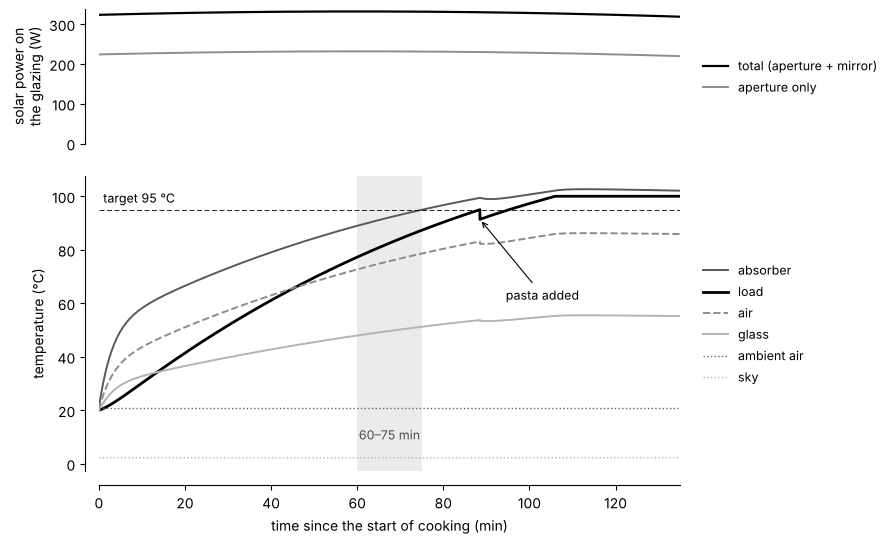

In [ ]:
t_h_all = t_start_h + t_all / 3600
P_all = np.array([P_solar(t, weather(t)) for t in t_h_all])   # (P, G_T, P_mirror)
Tsky_all = np.array([boundary(t)[1]['T_sky'] for t in t_h_all])

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(7.5, 6.0),
                               gridspec_kw=dict(height_ratios=[1, 2.2], hspace=0.15))
ax1.plot(t_min, P_all[:, 0], color='black', lw=1.6, label='total (aperture + mirror)')
ax1.plot(t_min, P_all[:, 1] * A_ap, color='0.55', lw=1.4, label='aperture only')
ax1.set_ylabel('solar power on\nthe glazing (W)')
ax1.set_ylim(0, None)
ax1.legend(frameon=False, loc='center left', bbox_to_anchor=(1.02, 0.5), fontsize=9)
style_axes(ax1, show_x=False)

line_styles = {'load': dict(color='black', lw=2.0),
               'absorber': dict(color='0.35', lw=1.4),
               'air': dict(color='0.55', lw=1.4, ls='--'),
               'glass': dict(color='0.70', lw=1.4)}
for name in ['absorber', 'load', 'air', 'glass']:          # legend in the order of the curves
    ax2.plot(t_min, theta[:, nodes.index(name)], label=name, **line_styles[name])
ax2.plot(t_min, np.full_like(t_min, Ta_C), color='0.4', ls=':', lw=1.0, label='ambient air')
ax2.plot(t_min, Tsky_all, color='0.7', ls=':', lw=1.0, label='sky')
ax2.axhline(T_target, color='black', lw=0.6, ls=(0, (6, 3)))
ax2.axvspan(60, 75, color='0.92', lw=0, zorder=0)                 # time window of the target
ax2.text(67.5, 8, '60–75 min', ha='center', va='bottom', fontsize=9, color='0.3')
ax2.text(1, T_target + 1.5, 'target 95 °C', ha='left', va='bottom', fontsize=9)
if t_pasta is not None:
    ax2.annotate('pasta added', xy=(t_pasta / 60, T_mix), xytext=(t_pasta / 60 + 6, T_mix - 30),
                 fontsize=9, arrowprops=dict(arrowstyle='->', color='black', lw=0.8))
ax2.set_xlabel('time since the start of cooking (min)')
ax2.set_ylabel('temperature (°C)')
ax2.set_xlim(0, t_min[-1])
ax2.legend(frameon=False, fontsize=9, loc='center left', bbox_to_anchor=(1.02, 0.5))
style_axes(ax2)
plt.show()

## 9. Steady state: stagnation temperatures

Setting $\dot{\boldsymbol\theta} = 0$ in Eq. (23) gives $\boldsymbol\theta = -\mathbf{K}^{-1}(\mathbf{K}_b\mathbf{b} + \mathbf{f})$, iterated
on $h_r$: the temperatures the cooker would reach at solar noon under constant conditions, **ignoring boiling**.
A load above 100 °C only means that the water would boil: compare with the measured stagnation temperatures of
slide 30.

In [ ]:
def stagnation(t_sol_h, n_iter=50):
    """Steady state of Eq. (23) (no load added, no boiling): theta = -K^-1 u, iterated on h_r."""
    wx, T = boundary(t_sol_h)
    P = P_solar(t_sol_h, wx)[0]
    th = np.full(n, 80.0)
    for _ in range(n_iter):
        G = G_vec(th, T)
        K, Kb = -A.T @ np.diag(G) @ A, A.T @ np.diag(G)
        th = np.linalg.solve(-K, Kb @ b_vec(T) + f_vec(P))
    return th

th_stag = stagnation(12.0)
for name, Tn in zip(nodes, th_stag):
    print(f"{name:9s}: {Tn:6.1f} degC")

glass    :   69.5 degC
air      :  109.9 degC
absorber :  125.6 degC
load     :  140.1 degC


## 10. Heat rates in the branches and energy check

Eqs. (20)–(21) give the heat rate in each branch. Over the simulated period, the solar energy absorbed by the nodes
must equal the energy stored in the capacities, plus the evaporation, plus the energy lost to the temperature sources
(ambient air and sky). The balance closes to the accuracy of the time integration.

In [ ]:
q = np.empty((t_all.size, m)); f = np.empty((t_all.size, n))
for i, (t, th) in enumerate(zip(t_h_all, theta)):
    wx, T = boundary(t)
    G = G_vec(th, T)
    q[i] = G * (-A @ th + b_vec(T))
    f[i] = f_vec(P_solar(t, wx)[0])

E_in = np.trapezoid(f.sum(axis=1), t_all)
E_stored = C_abs * (theta[-1, 2] - theta[0, 2]) + (C_load_t[-1] * theta[-1, 3] - C_load0 * theta[0, 3]) \
           - C_pasta * T_pasta * (t_pasta is not None)
# loss = heat leaving the nodes towards a temperature source
loss_k = np.array([(-1 if s[1] > 0 else 1) * np.trapezoid(q[:, k], t_all) if s else 0.0
                   for k, s in enumerate(source)])
# evaporation: net heat into the load when it is held at T_boil
net_load = (A.T @ q.T).T[:, 3] + f[:, 3]
E_evap = np.trapezoid(np.where(theta[:, 3] >= T_boil - 1e-6, np.maximum(net_load, 0), 0), t_all)
E_loss = loss_k.sum()

print(f"Solar energy absorbed : {E_in/1e3:8.1f} kJ")
print(f"Energy stored         : {E_stored/1e3:8.1f} kJ  ({100*E_stored/E_in:.1f} %)")
print(f"Evaporation           : {E_evap/1e3:8.1f} kJ  ({100*E_evap/E_in:.1f} %)")
for k, s in enumerate(source):
    if s:
        print(f"Loss, {branches[k][0]:16s}: {loss_k[k]/1e3:8.1f} kJ  ({100*loss_k[k]/E_in:.1f} %)")
print(f"Balance error         : {100*(E_in - E_stored - E_evap - E_loss)/E_in:.3f} %")

Solar energy absorbed :   2279.6 kJ
Energy stored         :    822.8 kJ  (36.1 %)
Evaporation           :    117.9 kJ  (5.2 %)
Loss, wind            :    463.0 kJ  (20.3 %)
Loss, sky             :    495.2 kJ  (21.7 %)
Loss, insulation      :    380.9 kJ  (16.7 %)
Balance error         : -0.013 %


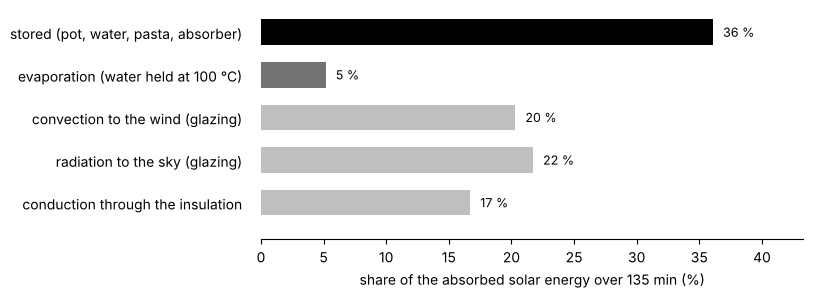

In [ ]:
loss_label = {'wind': 'convection to the wind (glazing)',
              'sky': 'radiation to the sky (glazing)',
              'insulation': 'conduction through the insulation'}
items = [('stored (pot, water, pasta, absorber)', E_stored), ('evaporation (water held at 100 °C)', E_evap)] + \
        [(loss_label[branches[k][0]], loss_k[k]) for k, s in enumerate(source) if s]
labels_b = [i[0] for i in items][::-1]
shares = np.array([i[1] for i in items])[::-1] / E_in * 100

fig, ax = plt.subplots(figsize=(7.0, 2.8))
bars = ax.barh(labels_b, shares, color=['0.75'] * (len(items) - 2) + ['0.45', 'black'], height=0.6)
for bar, v in zip(bars, shares):
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2, f"{v:.0f} %", va='center', fontsize=9)
ax.set_xlabel(f'share of the absorbed solar energy over {t_min[-1]:.0f} min (%)')
ax.set_xlim(0, max(shares) * 1.2)
style_axes(ax)
ax.tick_params(axis='y', length=0)
ax.spines['left'].set_visible(False)
plt.show()

## 11. Diagnosis: why the target is missed

The water reaches 95 °C after about 88 min instead of 60–75 min (the pasta phase itself is fine). The cell below
compares, over phase 1, the mean solar power absorbed by the cooker, the mean power lost to the ambient air and the
sky, and the mean net power that the water and the pot actually receive with the net power the target requires.

The deficit is a **design** problem, not a weather problem: compare the aperture of this example with the order of
magnitude of slide 41, and look at the bar chart above to see where the absorbed energy goes. Which parameters would
you change, and by how much? Answering this is the **sensitivity study** of the project (slide 43).

In [ ]:
# Why is the 60-75 min target missed? Compare the mean powers of phase 1 (water from 20 to 95 degC).
ph1 = t_all <= (t_pasta if t_pasta is not None else t_all[-1])
dt1 = t_all[ph1][-1] - t_all[ph1][0]
E_heat = C_load0 * (T_target - T_water0)                    # energy to bring pot + water to 95 degC
P_abs1  = np.trapezoid(f[ph1].sum(axis=1), t_all[ph1]) / dt1
P_loss1 = sum(np.trapezoid((-1 if s[1] > 0 else 1) * q[ph1, k], t_all[ph1]) for k, s in enumerate(source) if s) / dt1
print(f"Energy to heat pot + water to 95 degC  : {E_heat/1e3:6.0f} kJ")
print(f"Required mean net power (60-75 min)    : {E_heat/4500:6.0f} - {E_heat/3600:.0f} W")
print(f"Phase 1 in this example: absorbed {P_abs1:5.0f} W, lost {P_loss1:5.0f} W, "
      f"net into the load {E_heat/dt1:5.0f} W over {dt1/60:.0f} min")

Energy to heat pot + water to 95 degC  :    662 kJ
Required mean net power (60-75 min)    :    147 - 184 W
Phase 1 in this example: absorbed   283 W, lost   143 W, net into the load   125 W over 88 min


## 12. Going further in the project

* Replace `weather(t)` by the **EPW** data of your site and date (time conventions!); split beam and diffuse.
* Compute the **mirror term** from your geometry: $\cos\theta_m(t)$ and the fraction $\gamma(t)$ that reaches the
  aperture as the Sun moves (slide 30). Re-aiming every 20–30 min can be modelled as a reset of the mirror angle.
* Choose and justify the **convection correlations** (wind, enclosure, Duffie §3.11 and §3.15) and the
  **sky-temperature** model (slide 33).
* Run the **sensitivity study** (not included here): at least two design parameters (slide 43), for example aperture
  area, mirror size or tilt, glazing, insulation; then the wind.
* Compare with the **single-node model** of slide 37: lumping absorber and load into one node gives one capacity and
  one overall loss coefficient $U_L$. When does the single-node model become too optimistic (slide 44)?

**Reference.** I. Naveros, C. Ghiaus, J. Ordoñez, D. P. Ruiz (2016). *Thermal networks considering graph theory and
thermodynamics.* Proc. 12th Int. Conf. on Heat Transfer, Fluid Mechanics and Thermodynamics (HEFAT 2016), Málaga,
pp. 1568–1573.